# Homework

 **HW5-1:** Create a $100\times 100$ matrix of random numbers between 0 and 1
such that each entry is highly correlated with the adjacency entries. Find the SVD of the matrix. What fraction of the Frobenius norm of A is captured by the top 10 singular vectors? How many singular vectors are required to capture 95% of the Frobenius norm (the square root of the sum of the squares of all elements of the matrix)?
2. Repeat (1) with a $100\times 100$ matrix of statistically independent random numbers between 0 and 1.



In [52]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec # for the subplots

import pandas as pd
import seaborn as sns

# NOTE: these lines define global figure properties used for publication.
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg') # display figures in vector format
plt.rcParams.update({'font.size':14}) # set global font size



# Create some correlated data
X = np.random.randn(100,100)
X[:,1] = np.sum(X,axis=1)

# quick PCA
evals,evecs = np.linalg.eig( np.cov(X.T,ddof=1) )
scores = X @ evecs


Soultion

### **HW5-1**

Since $\|A\|_F^2 = \sum_i \sigma_i^2$, the fraction of the Frobenius norm captured by the top $k$ singular vectors (the rank-$k$ SVD approximation $A_k$) is

$$\frac{\|A_k\|_F}{\|A\|_F} = \sqrt{\frac{\sum_{i=1}^{k}\sigma_i^2}{\sum_{i=1}^{n}\sigma_i^2}}$$

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def norm_fraction(A, target=0.95):
    s = np.linalg.svd(A, compute_uv=False)
    frac = np.sqrt(np.cumsum(s**2) / np.sum(s**2))   # ||A_k||_F / ||A||_F
    k95 = np.argmax(frac >= target) + 1
    return s, frac, k95

def neighbor_corr(A):
    return np.corrcoef(A[:, :-1].ravel(), A[:, 1:].ravel())[0, 1]

np.random.seed(0)
# 1. correlated: smooth uniform random numbers with a Gaussian filter, then rescale to [0, 1]
A = gaussian_filter(np.random.rand(100, 100), sigma=5)
A = (A - A.min()) / (A.max() - A.min())
# 2. statistically independent random numbers in [0, 1]
B = np.random.rand(100, 100)

for name, Z in [('Correlated', A), ('Independent', B)]:
    s, frac, k95 = norm_fraction(Z)
    print(f"{name:12s} neighbor corr = {neighbor_corr(Z):.3f}   "
          f"top 10 capture {frac[9]:.4f} of ||.||_F   need {k95} for 95%")

Correlated   neighbor corr = 0.990   top 10 capture 1.0000 of ||.||_F   need 1 for 95%
Independent  neighbor corr = 0.001   top 10 capture 0.9052 of ||.||_F   need 26 for 95%


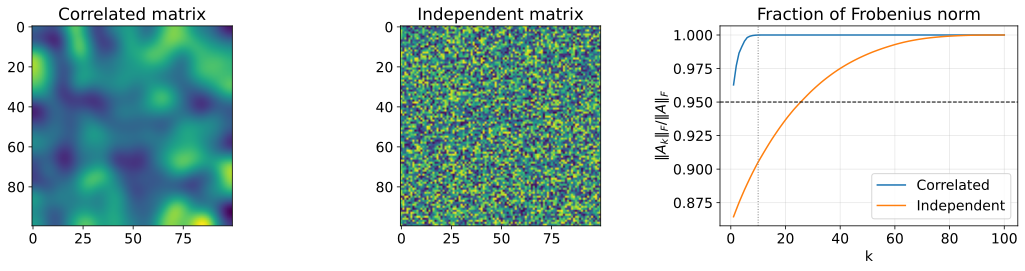

In [54]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(A, cmap='viridis'); ax[0].set_title('Correlated matrix')
ax[1].imshow(B, cmap='viridis'); ax[1].set_title('Independent matrix')
for name, Z in [('Correlated', A), ('Independent', B)]:
    s, frac, k95 = norm_fraction(Z)
    ax[2].plot(np.arange(1, 101), frac, label=name)
ax[2].axhline(0.95, color='k', ls='--', lw=1); ax[2].axvline(10, color='gray', ls=':', lw=1)
ax[2].set_xlabel('k'); ax[2].set_ylabel(r'$\|A_k\|_F / \|A\|_F$')
ax[2].set_title('Fraction of Frobenius norm'); ax[2].grid(alpha=0.3); ax[2].legend()
plt.tight_layout(); plt.show()

* Correlated matrix: the top 10 singular vectors capture essentially 100% of the Frobenius norm, and just 1 is enough for 95%. Neighboring entries are almost the same (corr 0.99), so the matrix is a smooth pattern, which is close to low rank. The first singular vector is basically the average level of the matrix, and the next few describe the slow variations.
* Independent matrix: the first singular value is still big because every entry has mean 0.5 (the rank-1 part $0.5\,\mathbf{1}\mathbf{1}^T$). After that the singular values are all about the same size, since the noise has no structure. The top 10 capture about 90% and 26 are needed for 95%.

**HW5-2:** (Finding Structure in Movie Ratings and Consumers): The 100K MovieLens dataset available at
https://grouplens.org/datasets/movielens/100k/. There are m = 1682 movies and n = 943 users. Each user rated at least 20 movies, but some watched many more. The total dataset contains 100, 000 total ratings from all users. Compute the singular value decomposition (SVD) corresponding matrix and suggest a way to capture the relationships of how people rate movies, and especially if there is a structure linking which people like which movies. You can interpret the left-singular vectors as stereotypical movies and
the right-singular vectors as stereotypical viewers. A specific movie is therefore represented by how it decomposes (linearly) into its stereotypical movies. Likewise, a person would be represented by how they decompose (via linear combination) into movie themes.


You can then make the assumption that any viewer's specific movie preferences can be expressed as a linear combination of the $v_j$. Similarly, any movie's like-ability can be expressed as a linear combination of the $u_i$. Therefore, a vector in the domain of the SVD can be interpreted as a viewer in the “space” of stereotypical viewers, and a vector in the codomain of the SVD correspondingly as a movie in the “space” of stereotypical movies. This can be the basis for recommending movies the users haven't seen (assuming that each
user would give a rating of 0 to any movie they have not reviewed). How can you use SVD to group a type of users with a specific set of movies?   

### **HW5-2**

Load the data and build the $1682\times 943$ rating matrix $R$ (rows = movies, columns = users, 0 = not rated). The download runs in Colab.

In [55]:
import os, urllib.request, zipfile
import pandas as pd
from sklearn.cluster import KMeans

if not os.path.exists('ml-100k'):
    urllib.request.urlretrieve('https://files.grouplens.org/datasets/movielens/ml-100k.zip', 'ml-100k.zip')
    zipfile.ZipFile('ml-100k.zip').extractall()

ratings = pd.read_csv('ml-100k/u.data', sep='\t', names=['user', 'movie', 'rating', 'time'])
titles = pd.read_csv('ml-100k/u.item', sep='|', encoding='latin-1', header=None)[1].values

m, n = 1682, 943
R = np.zeros((m, n))
R[ratings.movie - 1, ratings.user - 1] = ratings.rating
print(R.shape, " number of ratings:", np.count_nonzero(R))

(1682, 943)  number of ratings: 100000


#### SVD of $R$

$R = U\Sigma V^T$: columns of $U$ are stereotypical movies, columns of $V$ are stereotypical viewers. Signs are flipped so each $u_j$ has a positive sum (signs of singular vectors are arbitrary).

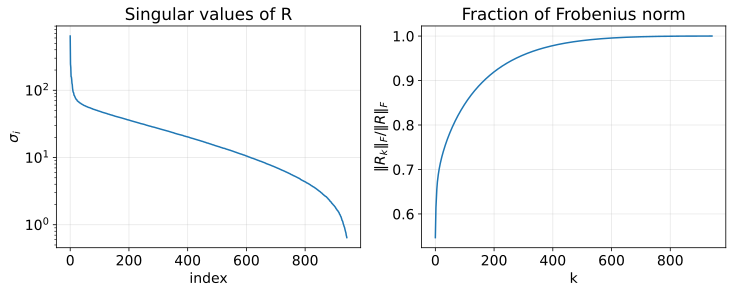

First 10 singular values: [640.6 244.8 217.8 159.2 158.2 145.9 126.6 121.9 106.8  99.7]


In [56]:
U, s, Vt = np.linalg.svd(R, full_matrices=False)
sgn = np.sign(U.sum(axis=0))
U, Vt = U * sgn, Vt * sgn[:, None]

energy = np.sqrt(np.cumsum(s**2) / np.sum(s**2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(s); ax[0].set_xlabel('index'); ax[0].set_ylabel(r'$\sigma_i$')
ax[0].set_title('Singular values of R'); ax[0].grid(alpha=0.3)
ax[1].plot(energy); ax[1].set_xlabel('k'); ax[1].set_ylabel(r'$\|R_k\|_F/\|R\|_F$')
ax[1].set_title('Fraction of Frobenius norm'); ax[1].grid(alpha=0.3)
plt.show()
print("First 10 singular values:", np.round(s[:10], 1))

#### Stereotypical movies

Movies with the largest (+) and smallest (−) entries in each of the first few left singular vectors.

In [57]:
for j in range(4):
    order = np.argsort(U[:, j])
    print(f"u{j+1}  (+):", list(titles[order[-5:][::-1]]))
    print(f"u{j+1}  (-):", list(titles[order[:5]]), "\n")

u1  (+): ['Star Wars (1977)', 'Raiders of the Lost Ark (1981)', 'Return of the Jedi (1983)', 'Fargo (1996)', 'Silence of the Lambs, The (1991)']
u1  (-): ['Further Gesture, A (1996)', "Mat' i syn (1997)", 'Very Natural Thing, A (1974)', 'Hush (1998)', 'Office Killer (1997)'] 

u2  (+): ['Contact (1997)', 'Scream (1996)', 'Air Force One (1997)', 'Liar Liar (1997)', 'Rock, The (1996)']
u2  (-): ['Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963)', 'Casablanca (1942)', 'Graduate, The (1967)', 'Citizen Kane (1941)', 'African Queen, The (1951)'] 

u3  (+): ['English Patient, The (1996)', 'L.A. Confidential (1997)', 'Full Monty, The (1997)', 'Secrets & Lies (1996)', 'Fargo (1996)']
u3  (-): ['Jurassic Park (1993)', 'True Lies (1994)', 'Top Gun (1986)', 'Speed (1994)', 'Batman (1989)'] 

u4  (+): ['Air Force One (1997)', 'Titanic (1997)', 'Conspiracy Theory (1997)', 'Good Will Hunting (1997)', 'Liar Liar (1997)']
u4  (-): ['Trainspotting (1996)', 'Twelve Monkeys (199

#### Grouping users with movies

Each user $i$ is represented by its coordinates in the space of the top $k$ stereotypical viewers, $\Sigma_k V_k^T e_i$. Users with similar coordinates like the same kinds of movies, so we cluster them with k-means. For each group, the movies it likes are the ones with the highest average score in the rank-$k$ approximation $R_k = U_k\Sigma_k V_k^T$.

In [58]:
k = 10
Rk = U[:, :k] @ np.diag(s[:k]) @ Vt[:k]          # rank-k approximation
users_k = (np.diag(s[:k]) @ Vt[:k]).T             # each row = one user in viewer space

groups = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(users_k)
for g in range(4):
    idx = groups == g
    top = np.argsort(Rk[:, idx].mean(axis=1))[-5:][::-1]
    print(f"Group {g} ({idx.sum()} users):", list(titles[top]))

Group 0 (249 users): ['Star Wars (1977)', 'Raiders of the Lost Ark (1981)', 'Return of the Jedi (1983)', 'Empire Strikes Back, The (1980)', 'Silence of the Lambs, The (1991)']
Group 1 (531 users): ['Contact (1997)', 'Air Force One (1997)', 'English Patient, The (1996)', 'Titanic (1997)', 'Star Wars (1977)']
Group 2 (66 users): ['Casablanca (1942)', 'Fargo (1996)', 'Citizen Kane (1941)', 'Godfather, The (1972)', 'Graduate, The (1967)']
Group 3 (97 users): ['Star Wars (1977)', 'Raiders of the Lost Ark (1981)', 'Empire Strikes Back, The (1980)', 'Return of the Jedi (1983)', 'Fugitive, The (1993)']


#### Recommending movies to a user

Use the rank-$k$ scores $R_k$ and recommend the highest-scoring movies the user has not rated.

In [59]:
user = 0
scores = Rk[:, user].copy()
scores[R[:, user] > 0] = -np.inf                  # skip movies already rated
print(f"Recommended for user {user + 1}:", list(titles[np.argsort(scores)[-5:][::-1]]))

Recommended for user 1: ['Trainspotting (1996)', 'Heathers (1989)', 'Close Shave, A (1995)', 'Sense and Sensibility (1995)', 'Batman (1989)']


* $R$ has nonnegative entries, so $u_1$ and $v_1$ have all the same sign: $u_1$ is basically movie popularity (how many / how high ratings a movie gets) and $v_1$ is how active each user is.
* The next singular vectors $u_2, u_3, \ldots$ have both signs and split the movies into opposite "themes" (the + and − lists above), and the matching $v_j$ say how much each user leans toward one side or the other.
* So a user's coordinates on $v_1,\ldots,v_k$ describe their taste. Clustering users in this space gives groups of similar viewers, and the rows of $U_k\Sigma_k$ (the movies) with the highest scores for that group are the set of movies that group likes. This is the structure that links people to movies.
* The same low-rank $R_k$ fills in the zeros and can be used for recommendations. One weakness: treating unrated movies as 0 means "not seen" looks like "disliked", which biases the results toward popular movies.